In [103]:
# Import liabraries

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

#  Model traning
from sklearn.model_selection import train_test_split

# Hyperparameter tuning and cross validation
from sklearn.model_selection import GridSearchCV,cross_val_score,RandomizedSearchCV
from sklearn.svm import SVR

# Scaling
from sklearn.preprocessing import StandardScaler

# model building
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# model evaluation
from sklearn.metrics import accuracy_score
from sklearn.metrics import mean_squared_error,r2_score,mean_absolute_error

#Warning
import warnings
warnings.filterwarnings('ignore')

In [3]:
import zipfile
with zipfile.ZipFile(r"/content/PRCP-1020-HousePricePred (2).zip", 'r') as zip_ref:
    zip_ref.extractall(r"/content/")

In [4]:
df=pd.read_csv("/content/Data/data.csv")

In [5]:
data=df

In [6]:
df

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125


In [7]:
#Data understanding

In [8]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [9]:
df.tail()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125
1459,1460,20,RL,75.0,9937,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,6,2008,WD,Normal,147500


In [10]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [11]:
df.dtypes

,0
Id,int64
MSSubClass,int64
MSZoning,object
LotFrontage,float64
LotArea,int64
...,...
MoSold,int64
YrSold,int64
SaleType,object
SaleCondition,object


In [12]:
 df.shape

(1460, 81)

In [13]:
print(df.columns)

Index(['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street',
       'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd',
       'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType',
       'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1',
       'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
       'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType',
       'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual',
       'GarageCond', 'PavedDrive

In [14]:
# Checking null & Duplicates

In [15]:
df.isnull().sum()

,0
Id,0
MSSubClass,0
MSZoning,0
LotFrontage,259
LotArea,0
...,...
MoSold,0
YrSold,0
SaleType,0
SaleCondition,0


In [16]:
df.duplicated().sum()

np.int64(0)

In [17]:
#Imputing Null values

In [18]:
df.loc[df['LotFrontage'].isnull(),'LotFrontage']=0

In [19]:
df.isnull().sum()

,0
Id,0
MSSubClass,0
MSZoning,0
LotFrontage,0
LotArea,0
...,...
MoSold,0
YrSold,0
SaleType,0
SaleCondition,0


In [20]:
df.loc[df['LotFrontage'].isnull(),'LotFrontage'].median()

nan

In [21]:
#EDA

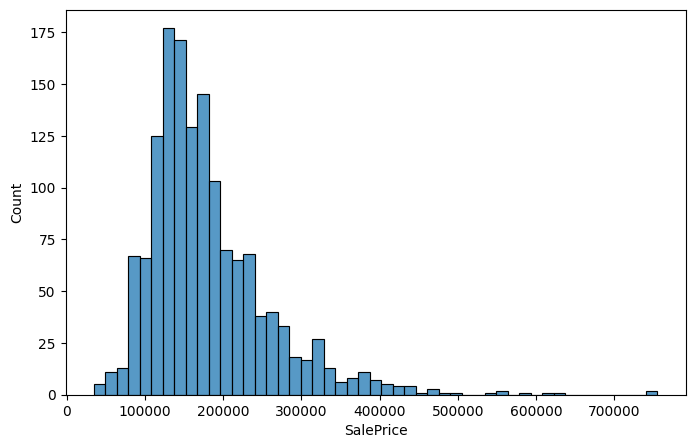

In [22]:
plt.figure(figsize=(8,5))
sns.histplot(x="SalePrice",data=df)
plt.show()

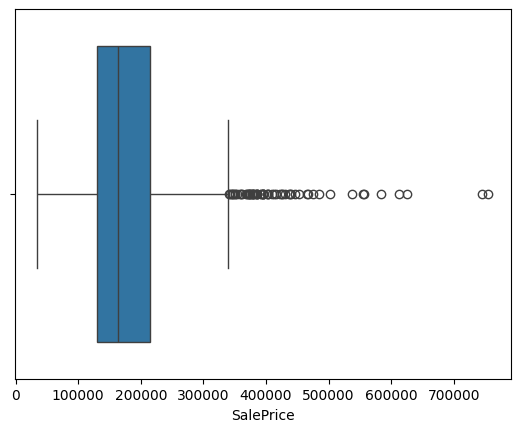

In [23]:
sns.boxplot(x=df["SalePrice"])
plt.show()

In [24]:
# Removing outliers

In [25]:
Q1 = df["SalePrice"].quantile(0.25)
Q3 = df["SalePrice"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

df = df[(df["SalePrice"] >= lower_limit) & (df["SalePrice"] <= upper_limit)]

print(df.shape)

(1399, 81)


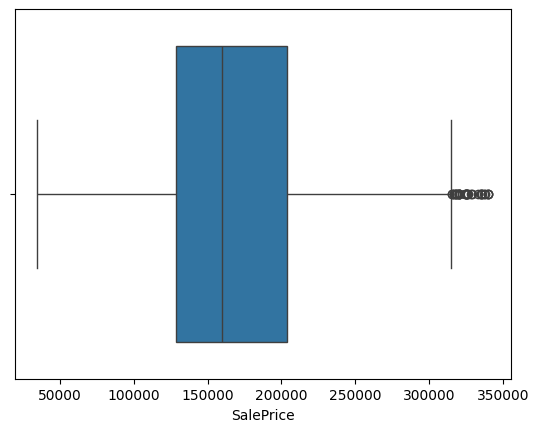

In [26]:
sns.boxplot(x=df["SalePrice"])
plt.show()

<Axes: >

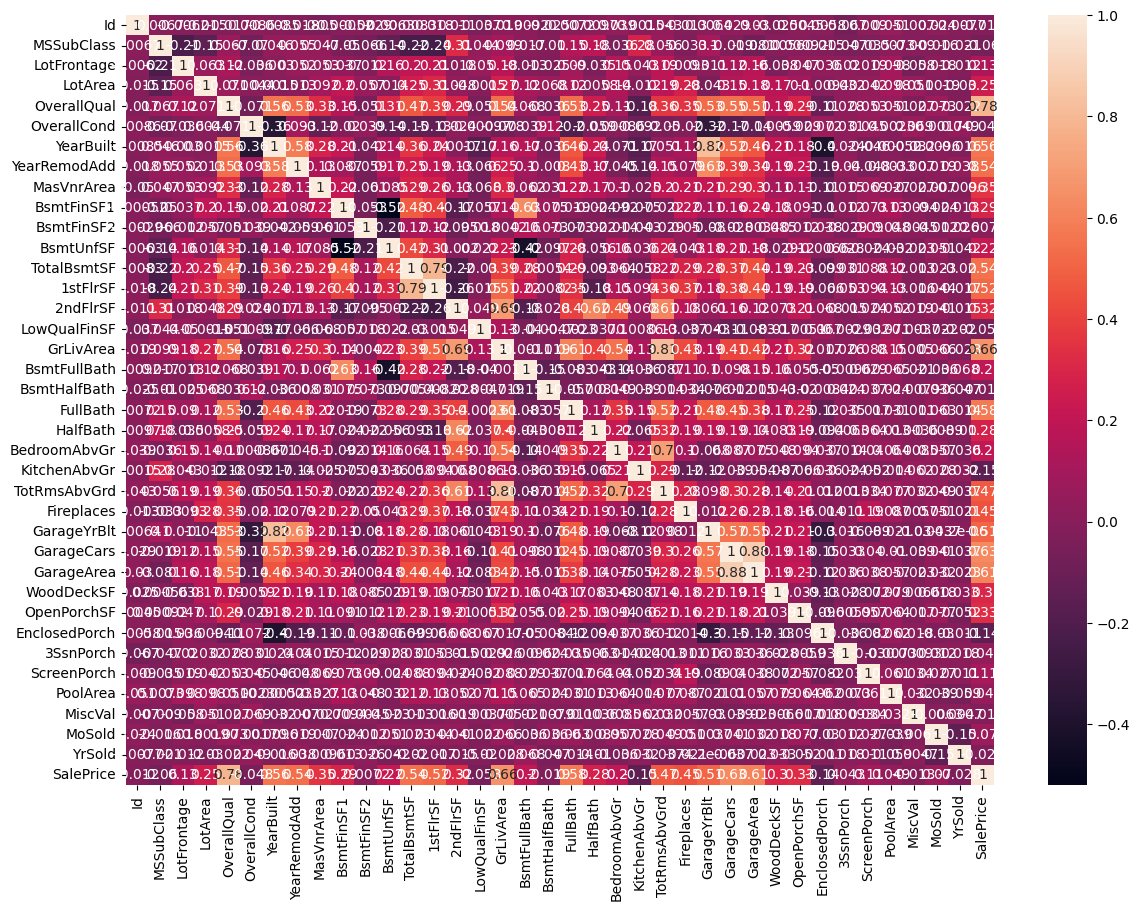

In [32]:
corr=df.corr(numeric_only=True)
plt.figure(figsize=(14,10))
sns.heatmap(corr,annot=True)

In [ ]:
# Features

In [34]:
df.columns

Index(['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street',
       'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd',
       'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType',
       'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1',
       'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
       'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType',
       'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual',
       'GarageCond', 'PavedDrive

In [35]:
df['HouseAge']=df['YrSold']-df['YearBuilt']

In [37]:
df['FullBath']=(df['FullBath']+df['BsmtFullBath']+0.5*df['HalfBath']+0.5*df['BsmtHalfBath'])

In [38]:
df['TotalArea']=(df['TotalBsmtSF']+df['1stFlrSF']+df['2ndFlrSF'])

In [39]:
# Encoding

In [41]:
df = pd.get_dummies(df, drop_first=True)

'''
“I used One-Hot Encoding with pd.get_dummies(drop_first=True) to convert nominal categorical
variables into numerical format. The drop_first=True parameter removes one category from each
feature to avoid multicollinearity, which is especially important for linear regression models.”
'''


In [42]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1399 entries, 0 to 1459
Columns: 248 entries, Id to SaleCondition_Partial
dtypes: bool(208), float64(4), int64(36)
memory usage: 732.3 KB


In [43]:
# Feature scaling

In [56]:
from sklearn.preprocessing import StandardScaler
Scaler= StandardScaler()
df_scaled = Scaler.fit_transform(df)

In [57]:
df.head()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,SaleType_ConLI,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
0,1,60,65.0,8450,7,5,2003,2003,196.0,706,...,False,False,False,False,True,False,False,False,True,False
1,2,20,80.0,9600,6,8,1976,1976,0.0,978,...,False,False,False,False,True,False,False,False,True,False
2,3,60,68.0,11250,7,5,2001,2002,162.0,486,...,False,False,False,False,True,False,False,False,True,False
3,4,70,60.0,9550,7,5,1915,1970,0.0,216,...,False,False,False,False,True,False,False,False,False,False
4,5,60,84.0,14260,8,5,2000,2000,350.0,655,...,False,False,False,False,True,False,False,False,True,False


In [60]:
# Train_Test_Split

In [76]:
X=df.drop("SalePrice",axis=1)

y=df["SalePrice"]

X_train,X_test,y_train,y_test=train_test_split(
df_scaled,
y,
test_size=0.2,
random_state=42
)

In [93]:
# Model Building

In [105]:
from sklearn.linear_model import LinearRegression
import numpy as np

# Calculate column-wise means from X_train, ignoring NaNs
X_train_col_means = np.nanmean(X_train, axis=0)

# Impute NaNs in X_train with the column means
X_train_imputed = np.where(np.isnan(X_train), X_train_col_means, X_train)

# Impute NaNs in X_test with the column means calculated from X_train
X_test_imputed = np.where(np.isnan(X_test), X_train_col_means, X_test)

lr = LinearRegression()
lr.fit(X_train_imputed, y_train)
pred = lr.predict(X_test_imputed)
lr_pred=lr.predict(X_test_imputed)

In [141]:
from sklearn.tree import DecisionTreeRegressor
DT=DecisionTreeRegressor()
DT.fit(X_train_imputed,y_train)
DT_pred=DT.predict(X_test_imputed)
# Removed accuracy_score calculation as it's not suitable for regression tasks.
# Evaluation metrics for regression (MAE, MSE, R2) are now collected in the results list in cell mLo4zOwvu0Fs.

In [112]:
# from sklearn.ensemble import RandomForestRegressorClassifier
RF=RandomForestRegressor()
RF.fit(X_train_imputed,y_train)
RF_pred=RF.predict(X_test_imputed)


In [142]:
from xgboost import XGBRegressor
XGB=XGBRegressor()
XGB.fit(X_train_imputed,y_train)
xgb_pred=XGB.predict(X_test_imputed)

In [94]:
# Model Evaluation

In [95]:
from sklearn.metrics import mean_squared_error,r2_score,mean_absolute_error

In [121]:
mean_absolute_error(y_test,lr_pred)

1.013956664662276e-10

In [116]:
mean_absolute_error(y_test,DT_pred)

922.9607142857143

In [117]:
mean_absolute_error(y_test,RF_pred)

209.60157142857233

In [114]:
r2_score(y_test,lr_pred)

'\nThis means your model explains about 99.77% of the variation in house prices.\n This is an extremely high score.\n'

In [118]:
r2_score(y_test,DT_pred)

0.9970911352411164

In [119]:
r2_score(y_test,RF_pred)

0.9999308971761771

In [120]:
mean_squared_error(y_test,lr_pred)

2.2530320117547198e-20

In [122]:
mean_squared_error(y_test,DT_pred)

9252567.632142857

In [123]:
mean_squared_error(y_test,RF_pred)

219803.4642349996

In [139]:
results=[]
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42)
}

In [145]:
import pandas as pd

comparison = pd.DataFrame(
    results,
    columns=[
        "Model",
        "MAE",
        "MSE",
        "R2 Score"
    ]
)

comparison

,Model,MAE,MSE,R2 Score
0,Linear Regression,1.013957e-10,2.253032e-20,1.00000
1,Decision Tree,3.774500e+02,6.672260e+05,0.99979
2,Random Forest,2.175879e+02,2.234693e+05,0.99993


In [161]:
# Hyperparameter Tunning

In [162]:
params= {'n_estimators':[100,200,300],
        'max_depth':[10,20,30]}

In [163]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor

grid=GridSearchCV(
    estimator=RandomForestRegressor(),
    param_grid=params, cv=5, scoring='r2' )

grid.fit(X_train_imputed,y_train)

GridSearchCV(cv=5, estimator=RandomForestRegressor(),
             param_grid={'max_depth': [10, 20, 30],
                         'n_estimators': [100, 200, 300]},
             scoring='r2')

In [165]:

# Best Parameters
print("Best Parameters:")
print(grid.best_params_)

# Best Cross Validation Accuracy
print("\nBest Cross Validation Accuracy:")
print(grid.best_score_)


Best Parameters:
{'max_depth': 20, 'n_estimators': 100}

Best Cross Validation Accuracy:
0.9997616232789703


In [ ]:
# Conclusion
'''
The developed model can be useful for:

Home buyers to estimate a fair property price.
Home sellers to decide an appropriate selling price.
Real estate agents to support pricing decisions.
Property investors to identify valuable investment opportunities.
'''